# NASDAQ Level 3 data Exploratory Data Analysis (EDA)

Exploratory analysis of one full trading day of Nasdaq TotalView-ITCH 5.0 data:
`S061226-v50.txt.gz`, 12 June 2026 (17.9 GB gzipped, ~1.3 billion messages, 12,810 order books).

**What the data looks like.** ITCH is Level 3 (order-by-order) data. Each book message is one event on one
order, identified by its order reference number: add (`A`/`F`), execute (`E`/`C`), partial cancel (`X`),
delete (`D`), replace (`U`). Replaying these events rebuilds every order book of the day. Session and symbol
messages (`S`, `R`, `H`, `h`) mark market phases, map locate codes to symbols and flag halts. The file is
parsed with [itch-book](https://github.com/groovg/itch-book) into Parquet tables and analysed with polars.
For the tool, the setup and what each event means, see [README.md](README.md).

**Goal.** Select a subset of symbols that is small enough to replay and test, and that is useful for:
- **covering different types of load** (most important): deep queues at a few price levels, very high
  message rates, wide and sparse books, heavy cancel/replace flow, and a realistic baseline;
- **load testing** the order book data structures with real order flow;
- **correctness validation**: replaying the chosen symbols must reproduce the recorded executions and the
  end-of-day book.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter, PercentFormatter

pl.Config.set_tbl_cols(-1)  # show every column instead of eliding the middle ones

polars.config.Config

In [2]:
DATA_PATH = "data/parquet"

messages = pl.scan_parquet(f"{DATA_PATH}/messages.parquet")
symbols = pl.scan_parquet(f"{DATA_PATH}/symbols.parquet")
trades = pl.scan_parquet(f"{DATA_PATH}/trades.parquet")
bbo = pl.scan_parquet(f"{DATA_PATH}/bbo.parquet")
halts = pl.scan_parquet(f"{DATA_PATH}/halts.parquet")
system_events = pl.scan_parquet(f"{DATA_PATH}/system_events.parquet")

In [3]:
TABLES = {
    "messages": messages,
    "symbols": symbols,
    "trades": trades,
    "bbo": bbo,
    "halts": halts,
    "system_events": system_events,
}


def table_sample(lf: pl.LazyFrame, rows: int, blocks: int = 100, block_size: int = 1_000, seed: int = 42) -> pl.DataFrame:
    """Random sample without reading the whole table: `blocks` slices of `block_size` consecutive rows
    at random offsets. Tables with at most `blocks * block_size` rows are returned whole."""
    if rows <= blocks * block_size:
        return lf.collect()
    rng = random.Random(seed)
    offsets = sorted(rng.sample(range(rows - block_size), blocks))
    return pl.concat([lf.slice(offset, block_size) for offset in offsets]).collect()


def overview(name: str, n_show: int = 10) -> None:
    """Attributes (column -> dtype), head, random rows and describe() of one table."""
    lf = TABLES[name]
    schema = lf.collect_schema()
    rows = lf.select(pl.len()).collect().item()
    sample = table_sample(lf, rows)
    sampled = sample.height < rows

    display(Markdown(f"### `{name}`: {rows:,} rows × {len(schema)} columns"))

    display(Markdown("#### Attributes"))
    # Object dtype only so the dtype names render without string quotes; the table is display-only.
    attributes = pl.DataFrame(
        {column: [str(dtype)] for column, dtype in schema.items()},
        schema={column: pl.Object for column in schema},
    )
    with pl.Config(tbl_hide_column_data_types=True, tbl_hide_dataframe_shape=True, fmt_str_lengths=100):
        display(attributes)

    display(Markdown("#### Head"))
    display(lf.head(n_show).collect())

    display(Markdown("#### Sample" + (f" (from {sample.height:,} random rows)" if sampled else "")))
    shown = sample.sample(min(n_show, sample.height), seed=42)
    display(shown.sort("seq") if "seq" in schema else shown)

    display(Markdown("#### Statistics" + (f" (on {sample.height:,} random rows)" if sampled else "")))
    display(sample.describe())

## Tables overview

A quick look at each table: which columns it has, what its rows look like and roughly what the values are.
**This is a highlight of the data, not precise numbers.** Any number used for a decision (e.g. symbol
selection) must come from a dedicated query over the full table, like `events_per_symbol` below.

For each table:
- **title**: the exact number of rows and columns;
- **Attributes**: every column and its type;
- **Head**: the first 10 rows of the table;
- **Sample**: 10 random rows;
- **Statistics**: `describe()`, i.e. count, nulls, mean, std, min, quartiles and max per column.

`symbols`, `halts` and `system_events` are small and loaded whole, so their Sample and Statistics are exact.

`messages` (1.29B rows), `bbo` (491M) and `trades` (28M) are too big to load into memory. To keep the
overview fast (a few seconds, a few hundred MB), their Sample and Statistics use 100,000 rows: 100 blocks of
1,000 consecutive rows taken at random positions in the table. For these three tables:
- count and nulls describe the sample, not the table;
- min and max are those of the sample: the true extremes are almost certainly missed;
- mean, std and quartiles are rough estimates: rows in one block come from the same few milliseconds of the
  day, so they are less precise than 100,000 independent rows would be.

In [4]:
overview("messages")

### `messages`: 1,289,917,161 rows × 14 columns

#### Attributes

ts_event,seq,locate,symbol,type,action,side,price,size,remaining,printable,order_id,old_order_id,mpid
"Datetime(time_unit='ns', time_zone='UTC')",UInt64,UInt16,Categorical,String,String,String,Int64,UInt32,UInt32,Boolean,UInt64,UInt64,UInt16


#### Head

ts_event,seq,locate,symbol,type,action,side,price,size,remaining,printable,order_id,old_order_id,mpid
"datetime[ns, UTC]",u64,u16,cat,str,str,str,i64,u32,u32,bool,u64,u64,u16
2026-06-12 08:00:00.000425736 UTC,309047,9268,"""QID""","""A""","""A""","""B""",146000,100,100,true,3,0,0
2026-06-12 08:00:00.000427018 UTC,309048,10087,"""SDS""","""A""","""A""","""B""",589000,100,100,true,4,0,0
2026-06-12 08:00:00.000443178 UTC,309049,3039,"""DIA""","""A""","""A""","""B""",5103800,100,100,true,2,0,0
2026-06-12 08:00:00.000444173 UTC,309050,9315,"""QQQ""","""A""","""A""","""B""",7159500,100,100,true,7,0,0
2026-06-12 08:00:00.000445388 UTC,309051,10622,"""SPXS""","""A""","""A""","""B""",277700,100,100,true,8,0,0
2026-06-12 08:00:00.000458729 UTC,309052,9276,"""QLD""","""A""","""A""","""B""",920000,100,100,true,11,0,0
2026-06-12 08:00:00.000460246 UTC,309053,10624,"""SPXU""","""A""","""A""","""B""",389800,100,100,true,12,0,0
2026-06-12 08:00:00.000461469 UTC,309054,6066,"""IVV""","""A""","""A""","""B""",7417700,100,100,true,6,0,0
2026-06-12 08:00:00.000472652 UTC,309055,9315,"""QQQ""","""A""","""A""","""S""",7161400,100,100,true,15,0,0


#### Sample (from 100,000 random rows)

ts_event,seq,locate,symbol,type,action,side,price,size,remaining,printable,order_id,old_order_id,mpid
"datetime[ns, UTC]",u64,u16,cat,str,str,str,i64,u32,u32,bool,u64,u64,u16
2026-06-12 13:50:13.493311485 UTC,172349525,9315,"""QQQ""","""A""","""A""","""S""",7126300,20,20,true,221991983,0,0
2026-06-12 14:01:06.042339790 UTC,223520293,5722,"""IGV""","""D""","""C""","""S""",902800,25,0,true,357497438,0,0
2026-06-12 14:49:29.455101287 UTC,417392819,8095,"""NVDA""","""D""","""C""","""B""",2042800,4,0,true,541928175,0,0
2026-06-12 15:41:38.999511431 UTC,626946045,11388,"""TSL""","""A""","""A""","""S""",155800,200,200,true,1122120300,0,0
2026-06-12 15:54:32.754509699 UTC,681658897,6154,"""JBGS""","""A""","""A""","""B""",144800,2,2,true,1114412506,0,0
2026-06-12 16:22:37.032043835 UTC,801627181,3868,"""EXC""","""D""","""C""","""S""",461100,25,0,true,1308989850,0,0
2026-06-12 17:06:23.024003367 UTC,914880547,2762,"""CVX""","""E""","""F""","""B""",1870400,12,28,true,1497344758,0,0
2026-06-12 17:37:55.502803360 UTC,981429813,5115,"""GXO""","""A""","""A""","""B""",496800,90,90,true,1607668290,0,0
2026-06-12 19:36:43.289269794 UTC,1205387088,6677,"""LCTU""","""A""","""A""","""B""",792100,200,200,true,1558504195,0,0


#### Statistics (on 100,000 random rows)

statistic,ts_event,seq,locate,symbol,type,action,side,price,size,remaining,printable,order_id,old_order_id,mpid
str,str,f64,f64,str,str,str,str,f64,f64,f64,f64,f64,f64,f64
"""count""","""100000""",100000.0,100000.0,"""100000""","""100000""","""100000""","""100000""",100000.0,100000.0,100000.0,100000.0,100000.0,100000.0,100000.0
"""null_count""","""0""",0.0,0.0,"""0""","""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2026-06-12 15:47:38.543132+00:…",6.0230e8,7136.21151,null,null,null,null,1.4956e6,248.72758,158.66806,1.0,9.1864e8,2.7226e8,0.14492
"""std""",null,3.5404e8,3706.943835,null,null,null,null,2.0640e6,3301.277168,3239.75123,null,5.8024e8,5.2303e8,2.545428
"""min""","""2026-06-12 09:21:21.690899+00:…",1.4333817e7,1.0,null,"""A""","""A""","""B""",1.0,1.0,0.0,1.0,75705.0,0.0,0.0
"""25%""","""2026-06-12 14:22:11.631716+00:…",3.10726889e8,4080.0,null,null,null,null,326300.0,40.0,0.0,null,4.41565676e8,0.0,0.0
"""50%""","""2026-06-12 15:27:24.782998+00:…",5.74028752e8,7530.0,null,null,null,null,776100.0,100.0,40.0,null,8.50116292e8,0.0,0.0
"""75%""","""2026-06-12 16:30:12.494841+00:…",8.23096278e8,10517.0,null,null,null,null,1.6177e6,100.0,100.0,null,1.3005e9,2.84846303e8,0.0
"""max""","""2026-06-12 19:58:32.272777+00:…",1.2815e9,12809.0,null,"""X""","""M""","""S""",5.2401e7,9.99999e5,9.99999e5,1.0,2.3504e9,2.3504e9,90.0


In [5]:
overview("symbols")

### `symbols`: 12,809 rows × 15 columns

#### Attributes

locate,symbol,market_category,financial_status,round_lot_size,round_lots_only,issue_classification,issue_subtype,authenticity,short_sale_threshold,ipo_flag,luld_tier,etp_flag,etp_leverage,inverse
UInt16,String,String,String,UInt32,Boolean,String,String,String,String,String,String,String,UInt32,String


#### Head

locate,symbol,market_category,financial_status,round_lot_size,round_lots_only,issue_classification,issue_subtype,authenticity,short_sale_threshold,ipo_flag,luld_tier,etp_flag,etp_leverage,inverse
u16,str,str,str,u32,bool,str,str,str,str,str,str,str,u32,str
1,"""A""","""N""",""" """,100,false,"""C""","""Z""","""P""","""N""",""" ""","""1""","""N""",0,"""N"""
2,"""AA""","""N""",""" """,100,false,"""C""","""Z""","""P""","""N""",""" ""","""1""","""N""",0,"""N"""
3,"""AAA""","""P""",""" """,100,false,"""Q""","""I""","""P""","""N""",""" ""","""2""","""Y""",0,"""N"""
4,"""AAAA""","""Z""",""" """,100,false,"""Q""","""I""","""P""","""N""",""" ""","""2""","""Y""",0,"""N"""
5,"""AAAC""","""P""",""" """,100,false,"""Q""","""I""","""P""","""N""",""" ""","""2""","""Y""",0,"""N"""
6,"""AAAD""","""P""",""" """,100,false,"""Q""","""I""","""P""","""N""",""" ""","""2""","""Y""",0,"""N"""
7,"""AAAU""","""Z""",""" """,100,false,"""Q""","""I""","""P""","""N""",""" ""","""1""","""Y""",0,"""N"""
8,"""AACB""","""G""","""D""",100,false,"""O""","""Z""","""P""","""N""","""N""","""2""","""N""",0,"""N"""
9,"""AACBR""","""G""","""N""",100,false,"""R""","""Z""","""P""","""N""","""N""",""" ""","""N""",0,"""N"""


#### Sample

locate,symbol,market_category,financial_status,round_lot_size,round_lots_only,issue_classification,issue_subtype,authenticity,short_sale_threshold,ipo_flag,luld_tier,etp_flag,etp_leverage,inverse
u16,str,str,str,u32,bool,str,str,str,str,str,str,str,u32,str
10424,"""SMZ""","""Z""",""" """,100,false,"""Q""","""I""","""P""","""N""",""" ""","""2""","""Y""",0,"""N"""
4082,"""FETH""","""Z""",""" """,100,false,"""Q""","""I""","""P""","""N""",""" ""","""1""","""Y""",0,"""N"""
12596,"""XT""","""G""","""N""",100,false,"""Q""","""I""","""P""","""N""","""N""","""1""","""Y""",1,"""N"""
8977,"""PQJL""","""G""","""N""",100,false,"""Q""","""I""","""P""","""N""","""N""","""2""","""Y""",1,"""N"""
10161,"""SFLR""","""P""",""" """,100,false,"""Q""","""I""","""P""","""N""",""" ""","""1""","""Y""",0,"""N"""
7531,"""MSW""","""S""","""N""",100,false,"""O""","""Z""","""P""","""N""","""N""","""2""","""N""",0,"""N"""
1606,"""BPACU""","""S""","""N""",100,false,"""U""","""Z""","""P""","""N""","""N""","""2""","""N""",0,"""N"""
7750,"""NCRA""","""S""","""D""",100,false,"""C""","""Z""","""P""","""N""","""N""","""2""","""N""",0,"""N"""
2661,"""CSRE""","""P""",""" """,100,false,"""Q""","""I""","""P""","""N""",""" ""","""2""","""Y""",0,"""N"""


#### Statistics

statistic,locate,symbol,market_category,financial_status,round_lot_size,round_lots_only,issue_classification,issue_subtype,authenticity,short_sale_threshold,ipo_flag,luld_tier,etp_flag,etp_leverage,inverse
str,f64,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,str
"""count""",12809.0,"""12809""","""12809""","""12809""",12809.0,12809.0,"""12809""","""12809""","""12809""","""12809""","""12809""","""12809""","""12809""",12809.0,"""12809"""
"""null_count""",0.0,"""0""","""0""","""0""",0.0,0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""",0.0,"""0"""
"""mean""",6405.0,null,null,null,98.716527,0.0,null,null,null,null,null,null,null,0.120228,null
"""std""",3697.784134,null,null,null,8.920933,null,null,null,null,null,null,null,null,0.379319,null
"""min""",1.0,"""A""","""A""",""" """,10.0,0.0,"""A""","""A""","""P""","""N""",""" """,""" ""","""N""",0.0,"""N"""
"""25%""",3203.0,null,null,null,100.0,null,null,null,null,null,null,null,null,0.0,null
"""50%""",6405.0,null,null,null,100.0,null,null,null,null,null,null,null,null,0.0,null
"""75%""",9607.0,null,null,null,100.0,null,null,null,null,null,null,null,null,0.0,null
"""max""",12809.0,"""ZYME""","""Z""","""N""",100.0,0.0,"""W""","""Z""","""T""","""Y""","""Y""","""2""","""Y""",3.0,"""Y"""


In [6]:
overview("trades")

### `trades`: 28,269,323 rows × 12 columns

#### Attributes

ts_event,seq,locate,symbol,kind,price,size,side,order_id,match_number,cross_type,broken
"Datetime(time_unit='ns', time_zone='UTC')",UInt64,UInt16,Categorical,String,Int64,UInt64,String,UInt64,UInt64,String,Boolean


#### Head

ts_event,seq,locate,symbol,kind,price,size,side,order_id,match_number,cross_type,broken
"datetime[ns, UTC]",u64,u16,cat,str,i64,u64,str,u64,u64,str,bool
2026-06-12 08:00:00.012083922 UTC,309652,5875,"""INTC""","""E""",1192900,3500,"""B""",2202,25597,"""N""",false
2026-06-12 08:00:00.020744411 UTC,309934,8117,"""NVO""","""E""",440600,10,"""B""",147,25598,"""N""",false
2026-06-12 08:00:00.020773473 UTC,309935,8117,"""NVO""","""E""",440600,10,"""B""",147,25599,"""N""",false
2026-06-12 08:00:00.026793266 UTC,309993,4910,"""GOOGL""","""E""",3591300,4,"""S""",2074,25600,"""N""",false
2026-06-12 08:00:00.026799314 UTC,310000,4910,"""GOOGL""","""E""",3591300,1,"""S""",2074,25601,"""N""",false
2026-06-12 08:00:00.026938658 UTC,310143,5388,"""HSHP""","""E""",148100,5,"""B""",2146,25602,"""N""",false
2026-06-12 08:00:00.026968384 UTC,310153,5316,"""HMY""","""E""",150600,1650,"""B""",3306,25603,"""N""",false
2026-06-12 08:00:00.027281321 UTC,310169,807,"""ASML""","""P""",18552300,1,"""N""",0,25604,"""N""",false
2026-06-12 08:00:00.036696910 UTC,310472,5316,"""HMY""","""E""",151000,57,"""B""",4086,25605,"""N""",false


#### Sample (from 100,000 random rows)

ts_event,seq,locate,symbol,kind,price,size,side,order_id,match_number,cross_type,broken
"datetime[ns, UTC]",u64,u16,cat,str,i64,u64,str,u64,u64,str,bool
2026-06-12 13:49:18.144545503 UTC,167048904,2709,"""CTSH""","""E""",509900,20,"""B""",264966906,3780163,"""N""",false
2026-06-12 14:07:43.029559634 UTC,253678705,4398,"""FRMI""","""P""",69800,26,"""N""",0,5351612,"""N""",false
2026-06-12 14:51:58.965733121 UTC,427323684,10517,"""SOXX""","""E""",5890000,10,"""B""",770966588,8319136,"""N""",false
2026-06-12 16:30:00.541145469 UTC,822417515,4039,"""FE""","""E""",466300,52,"""S""",1343504150,16634407,"""N""",false
2026-06-12 17:06:05.773950320 UTC,910914485,7564,"""MTUM""","""P""",3255200,100,"""N""",0,18380487,"""N""",false
2026-06-12 18:21:28.260921174 UTC,1066123356,938,"""AVGO""","""P""",3799700,40,"""N""",0,21682693,"""N""",false
2026-06-12 19:06:35.842282346 UTC,1145177286,178,"""ADBE""","""E""",2025000,51,"""S""",1154173097,23614416,"""N""",false
2026-06-12 19:16:47.710664656 UTC,1163621391,7797,"""NESR""","""E""",262300,3,"""B""",1499990379,24132682,"""N""",false
2026-06-12 19:54:00.052424514 UTC,1257108527,1058,"""BAK""","""P""",36750,1,"""N""",0,27045093,"""N""",false


#### Statistics (on 100,000 random rows)

statistic,ts_event,seq,locate,symbol,kind,price,size,side,order_id,match_number,cross_type,broken
str,str,f64,f64,str,str,f64,f64,str,f64,f64,str,f64
"""count""","""100000""",100000.0,100000.0,"""100000""","""100000""",100000.0,100000.0,"""100000""",100000.0,100000.0,"""100000""",100000.0
"""null_count""","""0""",0.0,0.0,"""0""","""0""",0.0,0.0,"""0""",0.0,0.0,"""0""",0.0
"""mean""","""2026-06-12 16:26:41.525247+00:…",7.0266e8,6823.65472,null,null,1.5097e6,84.21576,null,7.3261e8,1.4537e7,null,0.0
"""std""",null,4.0927e8,3850.974364,null,null,2.3038e6,448.879913,null,7.2823e8,8.6699e6,null,null
"""min""","""2026-06-12 09:44:03.095830+00:…",1.7863746e7,1.0,null,"""C""",115.0,1.0,"""B""",0.0,243659.0,"""N""",0.0
"""25%""","""2026-06-12 14:36:45.424777+00:…",3.66641691e8,3313.0,null,null,255050.0,7.0,null,0.0,7.341788e6,null,null
"""50%""","""2026-06-12 15:55:24.148010+00:…",6.84628317e8,7466.0,null,null,798500.0,28.0,null,5.41110227e8,1.38398e7,null,null
"""75%""","""2026-06-12 18:47:16.916191+00:…",1.1100e9,10536.0,null,null,1.6861e6,100.0,null,1.2775e9,2.2732512e7,null,null
"""max""","""2026-06-12 19:59:59.120437+00:…",1.2925e9,12809.0,null,"""P""",5.23288e7,50000.0,"""S""",2.3677e9,2.9415326e7,"""N""",0.0


In [7]:
overview("bbo")

### `bbo`: 491,197,723 rows × 10 columns

#### Attributes

ts_event,seq,locate,symbol,bid_px,bid_sz,bid_ct,ask_px,ask_sz,ask_ct
"Datetime(time_unit='ns', time_zone='UTC')",UInt64,UInt16,Categorical,Int64,UInt32,UInt32,Int64,UInt32,UInt32


#### Head

ts_event,seq,locate,symbol,bid_px,bid_sz,bid_ct,ask_px,ask_sz,ask_ct
"datetime[ns, UTC]",u64,u16,cat,i64,u32,u32,i64,u32,u32
2026-06-12 08:00:00.000425736 UTC,309047,9268,"""QID""",146000,100,1,0,0,0
2026-06-12 08:00:00.000427018 UTC,309048,10087,"""SDS""",589000,100,1,0,0,0
2026-06-12 08:00:00.000443178 UTC,309049,3039,"""DIA""",5103800,100,1,0,0,0
2026-06-12 08:00:00.000444173 UTC,309050,9315,"""QQQ""",7159500,100,1,0,0,0
2026-06-12 08:00:00.000445388 UTC,309051,10622,"""SPXS""",277700,100,1,0,0,0
2026-06-12 08:00:00.000458729 UTC,309052,9276,"""QLD""",920000,100,1,0,0,0
2026-06-12 08:00:00.000460246 UTC,309053,10624,"""SPXU""",389800,100,1,0,0,0
2026-06-12 08:00:00.000461469 UTC,309054,6066,"""IVV""",7417700,100,1,0,0,0
2026-06-12 08:00:00.000472652 UTC,309055,9315,"""QQQ""",7159500,100,1,7161400,100,1


#### Sample (from 100,000 random rows)

ts_event,seq,locate,symbol,bid_px,bid_sz,bid_ct,ask_px,ask_sz,ask_ct
"datetime[ns, UTC]",u64,u16,cat,i64,u32,u32,i64,u32,u32
2026-06-12 13:42:31.472316991 UTC,129048957,5039,"""GSPY""",400500,300,1,401400,400,2
2026-06-12 14:00:17.337977755 UTC,219185991,9304,"""QPUX""",313300,200,1,316600,200,1
2026-06-12 14:26:37.949190142 UTC,328706628,12092,"""VTV""",2164600,140,4,2164800,50,3
2026-06-12 16:02:49.742380603 UTC,716866806,11947,"""VIXY""",242500,45,3,242600,176,5
2026-06-12 16:15:13.813438470 UTC,773152089,7232,"""MGK""",867800,286,3,868000,339,3
2026-06-12 16:57:40.093895731 UTC,892556320,11228,"""TNA""",702700,60,2,702900,120,3
2026-06-12 17:47:31.417295779 UTC,999954132,758,"""ARR""",171400,1004,9,171600,600,5
2026-06-12 18:06:22.006794096 UTC,1035213333,11021,"""TEAM""",880100,37,2,880800,100,1
2026-06-12 19:34:50.199185607 UTC,1200019000,3225,"""DT""",407000,225,3,407200,146,4


#### Statistics (on 100,000 random rows)

statistic,ts_event,seq,locate,symbol,bid_px,bid_sz,bid_ct,ask_px,ask_sz,ask_ct
str,str,f64,f64,str,f64,f64,f64,f64,f64,f64
"""count""","""100000""",100000.0,100000.0,"""100000""",100000.0,100000.0,100000.0,100000.0,100000.0,100000.0
"""null_count""","""0""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2026-06-12 15:46:37.016962+00:…",6.0172e8,7200.96858,null,1.1880e6,2069.16463,3.60933,1.1897e6,2056.20619,3.5749
"""std""",null,3.8129e8,3731.076272,null,1.8547e6,12217.309269,4.229582,1.8560e6,11800.014462,4.055253
"""min""","""2026-06-12 08:37:42.412222+00:…",8.143122e6,1.0,null,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""","""2026-06-12 14:18:34.536613+00:…",2.96318656e8,4013.0,null,261700.0,100.0,1.0,262900.0,100.0,1.0
"""50%""","""2026-06-12 15:13:44.471837+00:…",5.34793189e8,7528.0,null,587100.0,210.0,2.0,587600.0,216.0,2.0
"""75%""","""2026-06-12 17:15:57.310720+00:…",9.38765744e8,10622.0,null,1.2149e6,691.0,5.0,1.2153e6,700.0,5.0
"""max""","""2026-06-12 19:55:28.905870+00:…",1.2650e9,12809.0,null,2.10904e7,465934.0,269.0,2.11065e7,351320.0,155.0


In [8]:
overview("halts")

### `halts`: 12,979 rows × 8 columns

#### Attributes

ts_event,seq,locate,symbol,kind,state,reason,market
"Datetime(time_unit='ns', time_zone='UTC')",UInt64,UInt16,Categorical,String,String,String,String


#### Head

ts_event,seq,locate,symbol,kind,state,reason,market
"datetime[ns, UTC]",u64,u16,cat,str,str,str,str
2026-06-12 07:04:57.196486632 UTC,65,1,"""A""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.198572799 UTC,132,2,"""AA""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.198983087 UTC,160,3,"""AAA""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.199528942 UTC,199,4,"""AAAA""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.202078561 UTC,202,5,"""AAAC""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.202154532 UTC,208,6,"""AAAD""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.202282816 UTC,219,7,"""AAAU""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.202444789 UTC,232,8,"""AACB""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.202642790 UTC,248,9,"""AACBR""","""H""","""T""","""""","""N"""


#### Sample

ts_event,seq,locate,symbol,kind,state,reason,market
"datetime[ns, UTC]",u64,u16,cat,str,str,str,str
2026-06-12 07:04:57.333030164 UTC,14856,1627,"""BRC""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.360845829 UTC,18201,2702,"""CTOR""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.387993896 UTC,21081,4142,"""FHTX""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.477575195 UTC,28071,7645,"""MYMF""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.480916122 UTC,28515,7867,"""NIHI""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.506647079 UTC,31001,9113,"""PSQO""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.532845518 UTC,33399,10313,"""SKYY""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.536661277 UTC,33933,10581,"""SPMO""","""H""","""T""","""""","""N"""
2026-06-12 07:04:57.563543550 UTC,37037,12133,"""WAGN""","""H""","""T""","""""","""N"""


#### Statistics

statistic,ts_event,seq,locate,symbol,kind,state,reason,market
str,str,f64,f64,str,str,str,str,str
"""count""","""12979""",12979.0,12979.0,"""12979""","""12979""","""12979""","""12979""","""12979"""
"""null_count""","""0""",0.0,0.0,"""0""","""0""","""0""","""0""","""0"""
"""mean""","""2026-06-12 07:12:21.437877+00:…",8.1575e6,6394.724093,null,null,null,null,null
"""std""",null,8.3005e7,3705.799154,null,null,null,null,null
"""min""","""2026-06-12 07:04:57.196486+00:…",65.0,1.0,null,"""H""","""H""","""""","""N"""
"""25%""","""2026-06-12 07:04:57.371109+00:…",19301.0,3177.0,null,null,null,null,null
"""50%""","""2026-06-12 07:04:57.459482+00:…",25789.0,6376.0,null,null,null,null,null
"""75%""","""2026-06-12 07:04:57.517080+00:…",32279.0,9610.0,null,null,null,null,null
"""max""","""2026-06-12 23:50:00.000308+00:…",1.3042e9,12809.0,null,"""H""","""T""","""T3""","""N"""


In [9]:
overview("system_events")

### `system_events`: 6 rows × 3 columns

#### Attributes

ts_event,seq,event
"Datetime(time_unit='ns', time_zone='UTC')",UInt64,String


#### Head

ts_event,seq,event
"datetime[ns, UTC]",u64,str
2026-06-12 07:01:32.008976642 UTC,1,"""O"""
2026-06-12 08:00:00.000105640 UTC,309046,"""S"""
2026-06-12 13:30:00.000052397 UTC,51563013,"""Q"""
2026-06-12 20:00:00.000026381 UTC,1292789520,"""M"""
2026-06-13 00:00:00.000018415 UTC,1304462501,"""E"""
2026-06-13 00:05:00.000020522 UTC,1304894064,"""C"""


#### Sample

ts_event,seq,event
"datetime[ns, UTC]",u64,str
2026-06-12 07:01:32.008976642 UTC,1,"""O"""
2026-06-12 08:00:00.000105640 UTC,309046,"""S"""
2026-06-12 13:30:00.000052397 UTC,51563013,"""Q"""
2026-06-12 20:00:00.000026381 UTC,1292789520,"""M"""
2026-06-13 00:00:00.000018415 UTC,1304462501,"""E"""
2026-06-13 00:05:00.000020522 UTC,1304894064,"""C"""


#### Statistics

statistic,ts_event,seq,event
str,str,f64,str
"""count""","""6""",6.0,"""6"""
"""null_count""","""0""",0.0,"""0"""
"""mean""","""2026-06-12 16:06:05.334866+00:…",6.5900e8,null
"""std""",null,7.0322e8,null
"""min""","""2026-06-12 07:01:32.008976+00:…",1.0,"""C"""
"""25%""","""2026-06-12 08:00:00.000105+00:…",309046.0,null
"""50%""","""2026-06-12 20:00:00.000026+00:…",1.2928e9,null
"""75%""","""2026-06-13 00:00:00.000018+00:…",1.3045e9,null
"""max""","""2026-06-13 00:05:00.000020+00:…",1.3049e9,"""S"""


In [10]:
events_per_symbol = (
    messages
    .group_by("locate")
    .agg(pl.len().alias("events"))
    .join(symbols.select("locate", "symbol"), on="locate", how="left")
    .select("symbol", "locate", "events")
    .sort("events", descending=True)
    .collect(engine="streaming")
)
print(f"{events_per_symbol.height:,} symbols with at least one event")

12,782 symbols with at least one event


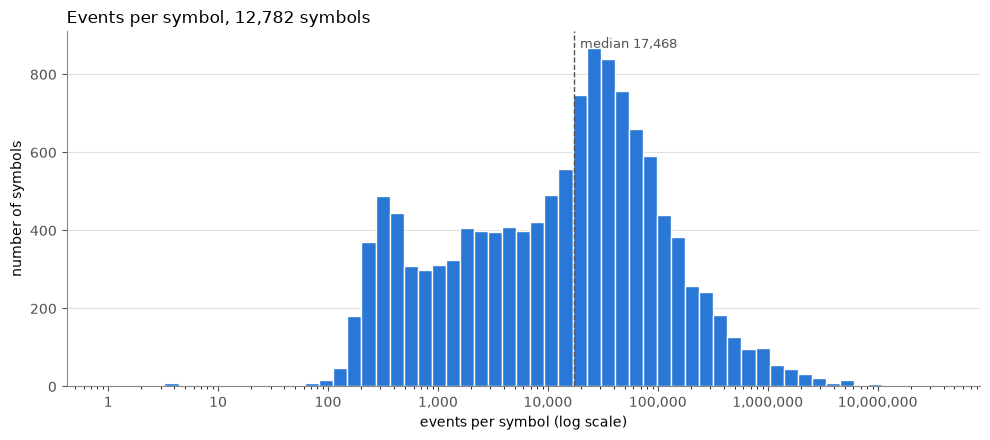

In [11]:
events = events_per_symbol["events"].to_numpy()
median = np.median(events)
bins = np.logspace(0, np.log10(events.max()) + 0.1, 60)  # log-spaced: counts range from 2 to 28M

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(events, bins=bins, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1)
ax.axvline(median, color="#52514e", linewidth=1, linestyle="--")
ax.annotate(
    f"median {median:,.0f}",
    xy=(median, 1), xycoords=("data", "axes fraction"),
    xytext=(4, -4), textcoords="offset points", va="top", fontsize=9, color="#52514e",
)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlabel("events per symbol (log scale)")
ax.set_ylabel("number of symbols")
ax.set_title(f"Events per symbol, {len(events):,} symbols", loc="left")
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#898781")
ax.tick_params(colors="#52514e")
fig.tight_layout()
plt.show()

In [12]:
top_n = 20
with pl.Config(tbl_rows=top_n):  # polars shows 10 rows by default and elides the middle
    display(events_per_symbol.head(top_n))

symbol,locate,events
str,u16,u32
"""QQQ""",9315,28415132
"""SPY""",10627,19654959
"""SPCX""",10536,18813350
"""XLK""",12493,14156219
"""TQQQ""",11300,12780957
"""IVV""",6066,10830396
"""NVDA""",8095,10747950
"""INTC""",5875,9301804
"""IWM""",6082,8890417


In [13]:
# Continuous-trading executions only: E and printable C (displayed orders), P (hidden orders).
# Q (one bulk print per auction cross) is left out; there are no broken (B) trades on this day.
trades_per_symbol = (
    trades
    .filter(pl.col("kind").is_in(["E", "C", "P"]))
    .group_by("locate")
    .agg(
        pl.len().alias("trades"),
        pl.col("kind").is_in(["E", "C"]).sum().alias("displayed"),
        (pl.col("kind") == "P").sum().alias("hidden"),
    )
    .join(symbols.select("locate", "symbol"), on="locate", how="left")
    .select("symbol", "locate", "trades", "displayed", "hidden")
    .sort("trades", descending=True)
    .collect(engine="streaming")
)
print(f"{trades_per_symbol.height:,} symbols with at least one trade")

10,865 symbols with at least one trade


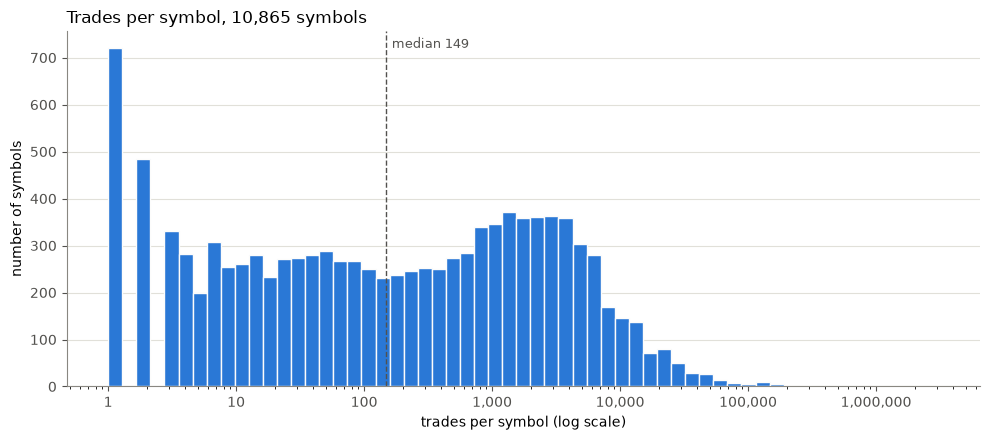

In [14]:
trade_counts = trades_per_symbol["trades"].to_numpy()
median = np.median(trade_counts)
bins = np.logspace(0, np.log10(trade_counts.max()) + 0.1, 60)  # log-spaced: counts range from 1 to 2.4M

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(trade_counts, bins=bins, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1)
ax.axvline(median, color="#52514e", linewidth=1, linestyle="--")
ax.annotate(
    f"median {median:,.0f}",
    xy=(median, 1), xycoords=("data", "axes fraction"),
    xytext=(4, -4), textcoords="offset points", va="top", fontsize=9, color="#52514e",
)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlabel("trades per symbol (log scale)")
ax.set_ylabel("number of symbols")
ax.set_title(f"Trades per symbol, {len(trade_counts):,} symbols", loc="left")
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#898781")
ax.tick_params(colors="#52514e")
fig.tight_layout()
plt.show()

In [15]:
with pl.Config(tbl_rows=top_n):
    display(trades_per_symbol.head(top_n))

symbol,locate,trades,displayed,hidden
str,u16,u32,u32,u32
"""SPCX""",10536,2442377,1683121,759256
"""NVDA""",8095,364988,267033,97955
"""INTC""",5875,308795,227818,80977
"""MU""",7571,265075,170353,94722
"""TSLA""",11389,243140,152095,91045
"""QQQ""",9315,227811,194725,33086
"""RKLB""",9649,187751,110370,77381
"""SPY""",10627,187058,163294,23764
"""SOXL""",10514,174083,128550,45533


In [16]:
EVENT_GROUPS = {  # dominant type first: it is drawn at the bottom of the bars, in the first colour
    "add": ["A", "F"],
    "fill": ["E", "C"],
    "cancel": ["D", "X"],
    "replace": ["U"],
}
EVENT_TYPES = [event_type for types in EVENT_GROUPS.values() for event_type in types]
MIN_EVENTS = 100_000  # shares of symbols with few events are noise (2 events -> 0% / 50% / 100%)

event_mix_per_symbol = (
    messages
    .group_by("locate")
    .agg(
        pl.len().alias("events"),
        *[(pl.col("type") == event_type).sum().alias(event_type) for event_type in EVENT_TYPES],
    )
    .filter(pl.col("events") >= MIN_EVENTS)
    .with_columns([pl.sum_horizontal(types).alias(group) for group, types in EVENT_GROUPS.items()])
    .with_columns([(pl.col(group) / pl.col("events") * 100).alias(f"{group}_pct") for group in EVENT_GROUPS])
    .join(symbols.select("locate", "symbol"), on="locate", how="left")
    .select("symbol", "locate", "events", *EVENT_TYPES, *EVENT_GROUPS, *[f"{group}_pct" for group in EVENT_GROUPS])
    .sort("events", descending=True)
    .collect(engine="streaming")
)
print(f"{event_mix_per_symbol.height:,} symbols with at least {MIN_EVENTS:,} events")

1,990 symbols with at least 100,000 events


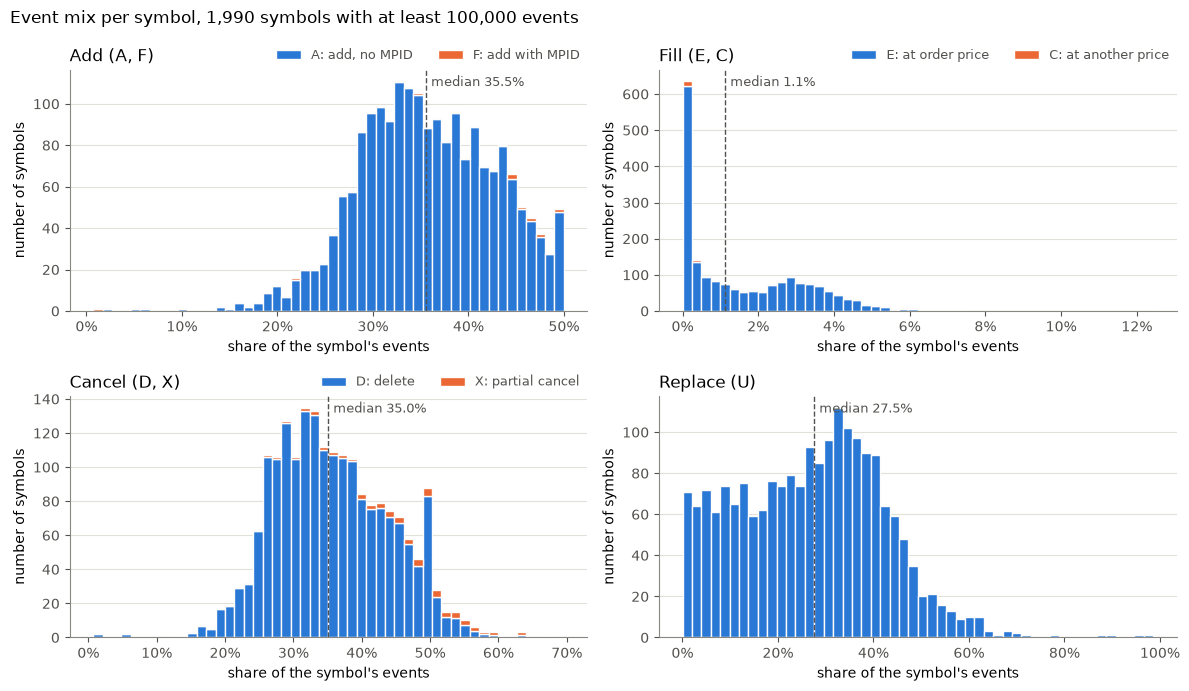

In [17]:
TYPE_COLORS = ["#2a78d6", "#eb6834"]  # first type of a group at the bottom of the bar, second on top
TYPE_LABELS = {
    "A": "A: add, no MPID", "F": "F: add with MPID",
    "E": "E: at order price", "C": "C: at another price",
    "D": "D: delete", "X": "X: partial cancel",
    "U": "U: replace",
}
N_BINS = 50

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (group, types) in zip(axes.flat, EVENT_GROUPS.items()):
    shares = event_mix_per_symbol[f"{group}_pct"].to_numpy()
    edges = np.histogram_bin_edges(shares, bins=N_BINS)
    bin_of = np.clip(np.digitize(shares, edges) - 1, 0, N_BINS - 1)
    symbols_in_bin = np.bincount(bin_of, minlength=N_BINS)
    group_events = event_mix_per_symbol[group].to_numpy()

    # Split each bar by the mean (over the symbols in the bin) of each type's fraction of the group's events.
    # Symbols with no events in the group (14 symbols have no fills) don't count towards the mean.
    has_group_events = group_events > 0
    symbols_with_events = np.bincount(bin_of, weights=has_group_events, minlength=N_BINS)
    bottom = np.zeros(N_BINS)
    for i, (event_type, color) in enumerate(zip(types, TYPE_COLORS)):
        if i == len(types) - 1:
            height = symbols_in_bin - bottom  # the last type takes the rest of the bar
        else:
            type_fraction = np.divide(
                event_mix_per_symbol[event_type].to_numpy(), group_events,
                out=np.zeros(len(shares)), where=has_group_events,
            )
            fraction_sum = np.bincount(bin_of, weights=type_fraction, minlength=N_BINS)
            mean_fraction = np.divide(
                fraction_sum, symbols_with_events,
                out=np.zeros(N_BINS), where=symbols_with_events > 0,
            )
            height = symbols_in_bin * mean_fraction
        ax.bar(
            edges[:-1], height, width=np.diff(edges), bottom=bottom, align="edge",
            color=color, edgecolor="#fcfcfb", linewidth=1, label=TYPE_LABELS[event_type],
        )
        bottom += height

    median = np.median(shares)
    ax.axvline(median, color="#52514e", linewidth=1, linestyle="--")
    ax.annotate(
        f"median {median:.1f}%",
        xy=(median, 1), xycoords=("data", "axes fraction"),
        xytext=(4, -4), textcoords="offset points", va="top", fontsize=9, color="#52514e",
    )
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xlabel("share of the symbol's events")
    ax.set_ylabel("number of symbols")
    ax.set_title(f"{group.capitalize()} ({', '.join(types)})", loc="left")
    if len(types) > 1:
        ax.legend(
            frameon=False, fontsize=9, loc="lower right", bbox_to_anchor=(1, 1), ncols=2,
            labelcolor="#52514e", borderaxespad=0.2,
        )
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#898781")
    ax.tick_params(colors="#52514e")
fig.suptitle(
    f"Event mix per symbol, {event_mix_per_symbol.height:,} symbols with at least {MIN_EVENTS:,} events",
    x=0.01, ha="left",
)
fig.tight_layout()
plt.show()

### Why the event mix does not separate load types

Every order is added once (`A`/`F`) and leaves the book once: by a delete (`D`), by a full execution, or it is still
resting at the close. A replace (`U`) is a delete and an add in one message: the old order leaves the book and a new one
(new reference number, same side) enters it. So, for the 1,990 symbols with at least 100,000 events:

- **Add and cancel shares are tied together** (left plot, r = 0.88). 1,541 symbols are within 3 percentage points of
  `add = cancel`. Symbols below the diagonal are fill-heavy: part of their orders leave by execution instead of a delete
  (median fill share 4.4% vs 0.9%). Symbols above it are partial-cancel-heavy: one order can receive several `X`
  (median `X` share 7.5% vs 0.2%).
- **Replaces take their share from add and cancel equally** (right plot): both follow `(100% − replace) / 2`. The
  replace share only tells how often orders are repriced in place instead of being deleted and sent again.
- **Fills are small**: median 1.1% of a symbol's events, below 6.2% for 99% of the symbols. Most orders are cancelled,
  not executed: across these symbols there are 22.5 cancels (`D`, `X`) per execution (`E`, `C`) on this day.

For the order book data structures, a `U` is a removal plus an insertion, the same operations as a `D` followed by an
`A`. The mix tells how many structure operations one message carries, not which ones, so taking symbols from either end
of these distributions does not give a different type of load. What distinguishes loads is where the orders go: the
price range, the number of active price levels, the distance from the best price, and how often levels are created and
emptied.

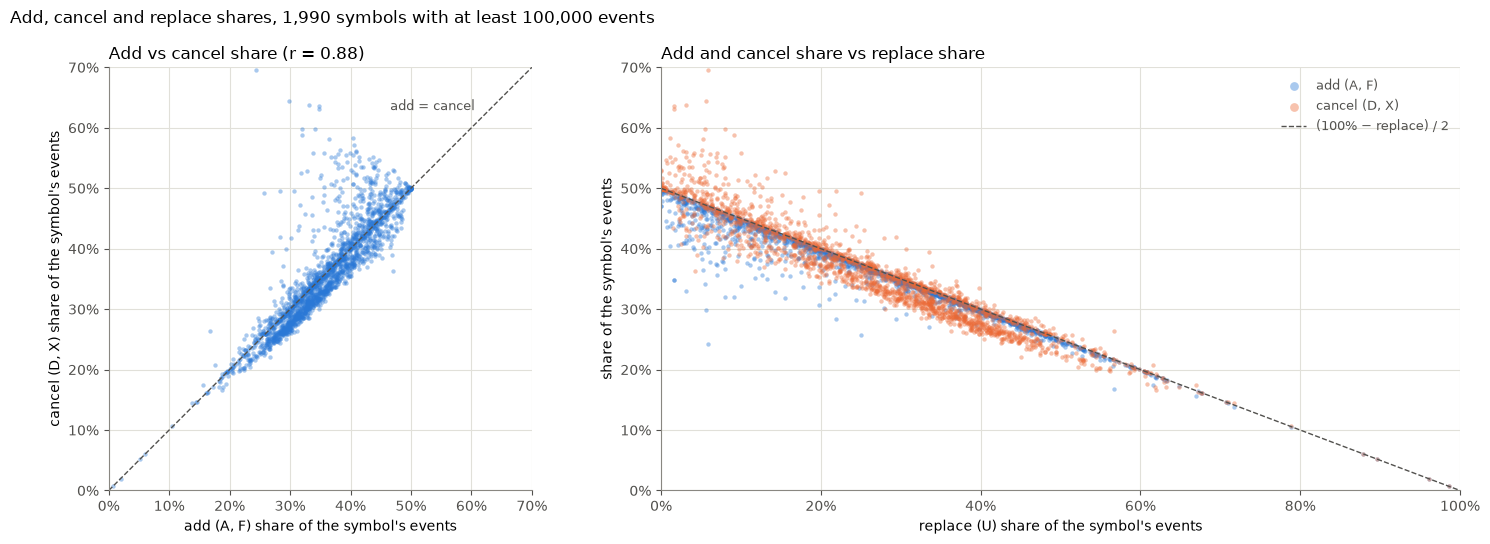

In [18]:
add = event_mix_per_symbol["add_pct"].to_numpy()
cancel = event_mix_per_symbol["cancel_pct"].to_numpy()
replace = event_mix_per_symbol["replace_pct"].to_numpy()
r = np.corrcoef(add, cancel)[0, 1]

fig, (ax_tie, ax_replace) = plt.subplots(1, 2, figsize=(15, 5.5), width_ratios=[1, 1.6])

# Left: add vs cancel share, one point per symbol.
ax_tie.scatter(add, cancel, s=10, color="#2a78d6", alpha=0.4, linewidths=0)
ax_tie.plot([0, 70], [0, 70], color="#52514e", linewidth=1, linestyle="--")
ax_tie.annotate("add = cancel", xy=(62, 62), xytext=(-6, 4), textcoords="offset points", ha="right", fontsize=9, color="#52514e")
ax_tie.set_xlim(0, 70)
ax_tie.set_ylim(0, 70)
ax_tie.set_aspect("equal")
ax_tie.set_xlabel("add (A, F) share of the symbol's events")
ax_tie.set_ylabel("cancel (D, X) share of the symbol's events")
ax_tie.set_title(f"Add vs cancel share (r = {r:.2f})", loc="left")

# Right: add and cancel share against replace share.
line_x = np.array([0, 100])
ax_replace.scatter(replace, add, s=10, color="#2a78d6", alpha=0.4, linewidths=0, label="add (A, F)")
ax_replace.scatter(replace, cancel, s=10, color="#eb6834", alpha=0.4, linewidths=0, label="cancel (D, X)")
ax_replace.plot(line_x, (100 - line_x) / 2, color="#52514e", linewidth=1, linestyle="--", label="(100% − replace) / 2")
ax_replace.set_xlim(0, 100)
ax_replace.set_ylim(0, 70)
ax_replace.set_xlabel("replace (U) share of the symbol's events")
ax_replace.set_ylabel("share of the symbol's events")
ax_replace.set_title("Add and cancel share vs replace share", loc="left")
ax_replace.legend(frameon=False, fontsize=9, labelcolor="#52514e", markerscale=2)

for ax in (ax_tie, ax_replace):
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#898781")
    ax.tick_params(colors="#52514e")
fig.suptitle(f"Add, cancel and replace shares, {len(add):,} symbols with at least {MIN_EVENTS:,} events", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## Price profile per symbol

Where orders are placed matters more for the data structures than which event types arrive. This section profiles
the prices orders are placed at: adds (`A`, `F`) and the new half of replaces (`U`), over the **whole day**, since the
book has to hold every resting order, including those placed before the open. Rows the book rejected (zero shares or
zero price) are left out.

One streaming pass over `messages` (about 15 s, ~2.6 GB peak) gives per symbol:
- **orders**, **mean price**, **lowest and highest order price**;
- **range in ticks** between the lowest and highest price: the number of slots an array indexed by price would need.
  A tick is $0.01 from $1 up and $0.0001 below $1 (Reg NMS). Checked for orders placed during market hours: every
  one at or above $1 is on the 1-cent grid;
- **distinct prices**: how many different prices orders were placed at, i.e. how many price levels the book used over
  the day. Counted approximately with HyperLogLog (`approx_n_unique`, about 1% error), because an exact count needs a
  set of every price per symbol, which does not fit in memory;
- **density**: distinct prices / range in ticks.

In [19]:
ONE_DOLLAR = 10_000  # prices are integers in 1/10,000 USD

# Where orders are placed, over the whole day: adds (A, F) and the new half of replaces (U).
# Rows the book rejected (zero shares or price) have remaining == 0.
arrivals = messages.filter(pl.col("action").is_in(["A", "M"]), pl.col("remaining") > 0)


def tick_index(price: pl.Expr) -> pl.Expr:
    """Position of a price on the Reg NMS grid: $0.0001 steps below $1, $0.01 steps from $1 up."""
    return pl.when(price < ONE_DOLLAR).then(price).otherwise(ONE_DOLLAR + (price - ONE_DOLLAR) // 100)

In [20]:
# One streaming pass, one row per symbol: only running values per symbol, so memory stays small.
price_profile = (
    arrivals
    .group_by("locate")
    .agg(
        pl.len().alias("orders"),
        (pl.col("price").mean() / ONE_DOLLAR).alias("mean_price_usd"),
        pl.col("price").min().alias("min_px"),
        pl.col("price").max().alias("max_px"),
        pl.col("price").approx_n_unique().alias("distinct_prices"),  # HyperLogLog estimate, ~1% error
    )
    .with_columns((tick_index(pl.col("max_px")) - tick_index(pl.col("min_px")) + 1).alias("range_ticks"))
    .with_columns((pl.col("distinct_prices") / pl.col("range_ticks")).alias("density"))
    .join(symbols.select("locate", "symbol", "ipo_flag"), on="locate", how="left")
    .select("symbol", "locate", "orders", "mean_price_usd", "min_px", "max_px", "range_ticks", "distinct_prices", "density", "ipo_flag")
    .sort("orders", descending=True)
    .collect(engine="streaming")
)
print(f"{price_profile.height:,} symbols with orders")

12,782 symbols with orders


In [21]:
active_price_profile = price_profile.join(event_mix_per_symbol.select("locate"), on="locate", how="semi")

# How many active symbols share the same lowest and highest order price (USD only for display).
price_bounds = (
    active_price_profile
    .group_by("min_px", "max_px", "range_ticks")
    .agg(pl.len().alias("symbols"))
    .with_columns(
        (pl.col("min_px") / ONE_DOLLAR).alias("lowest_usd"),
        (pl.col("max_px") / ONE_DOLLAR).alias("highest_usd"),
        (pl.col("symbols") / active_price_profile.height * 100).alias("share_pct"),
    )
    .select("lowest_usd", "highest_usd", "range_ticks", "symbols", "share_pct")
    .sort("symbols", descending=True)
)
print(f"{price_bounds.height:,} different (lowest, highest) price pairs among {active_price_profile.height:,} symbols")
price_bounds.head(10)

1,040 different (lowest, highest) price pairs among 1,990 symbols


lowest_usd,highest_usd,range_ticks,symbols,share_pct
f64,f64,i64,u32,f64
0.0001,199999.0,20009800,898,45.125628
0.0001,2147.48,224648,17,0.854271
0.01,999.99,109800,12,0.603015
1.0,100.0,9901,5,0.251256
0.01,100.0,19801,4,0.201005
0.01,2000.0,209801,3,0.150754
1.0,999.99,99900,3,0.150754
4.5,150.0,14551,2,0.100503
3.0,100.0,9701,2,0.100503


In [22]:
REFERENCE_SYMBOLS = ["AAPL", "NVDA", "MSFT", "SPY", "QQQ"]  # popular names, for comparison
N_OUTLIERS = 5
PROFILE_COLUMNS = ["symbol", "orders", "mean_price_usd", "min_px", "max_px", "range_ticks", "distinct_prices", "density"]

most_distinct = active_price_profile.sort("distinct_prices", descending=True).head(N_OUTLIERS)
least_distinct = active_price_profile.sort("distinct_prices").head(N_OUTLIERS)
references = active_price_profile.filter(pl.col("symbol").is_in(REFERENCE_SYMBOLS)).sort("distinct_prices", descending=True)

display(Markdown(f"**Top {N_OUTLIERS} by distinct prices** (symbols with at least {MIN_EVENTS:,} events)"))
display(most_distinct.select(PROFILE_COLUMNS))
display(Markdown(f"**Bottom {N_OUTLIERS} by distinct prices** (symbols with at least {MIN_EVENTS:,} events)"))
display(least_distinct.select(PROFILE_COLUMNS))
display(Markdown("**Reference symbols**"))
display(references.select(PROFILE_COLUMNS))

**Top 5 by distinct prices** (symbols with at least 100,000 events)

symbol,orders,mean_price_usd,min_px,max_px,range_ticks,distinct_prices,density
str,u32,f64,i64,i64,i64,u32,f64
"""SNDK""",775896,1956.243453,1,1999990000,20009800,31940,0.001596
"""MU""",2425958,985.266923,1,1999990000,20009800,22174,0.001108
"""SPCX""",9640608,161.163555,1,1999990000,20009800,21090,0.001054
"""ASML""",2274541,1862.584049,1,1999990000,20009800,20577,0.001028
"""TSLA""",3296106,399.505951,1,1999990000,20009800,18385,0.000919


**Bottom 5 by distinct prices** (symbols with at least 100,000 events)

symbol,orders,mean_price_usd,min_px,max_px,range_ticks,distinct_prices,density
str,u32,f64,i64,i64,i64,u32,f64
"""SPDN""",53245,8.825426,36300,140500,1043,108,0.103547
"""DAMD""",72148,1.975219,9020,78000,1661,112,0.067429
"""MSC""",116906,2.531773,9320,199900,2580,135,0.052326
"""TZA""",220524,4.146318,17400,111100,938,137,0.146055
"""CCUP""",71936,2.625876,11600,100000,885,146,0.164972


**Reference symbols**

symbol,orders,mean_price_usd,min_px,max_px,range_ticks,distinct_prices,density
str,u32,f64,i64,i64,i64,u32,f64
"""MSFT""",2141779,390.13739,1,1999990000,20009800,15892,0.000794
"""QQQ""",18633724,719.736422,1,1999990000,20009800,15517,0.000775
"""NVDA""",7105757,205.233336,1,1999990000,20009800,13556,0.000677
"""AAPL""",4295214,291.813935,1,1999990000,20009800,9489,0.000474
"""SPY""",13028624,740.960516,1,1999990000,20009800,7596,0.00038


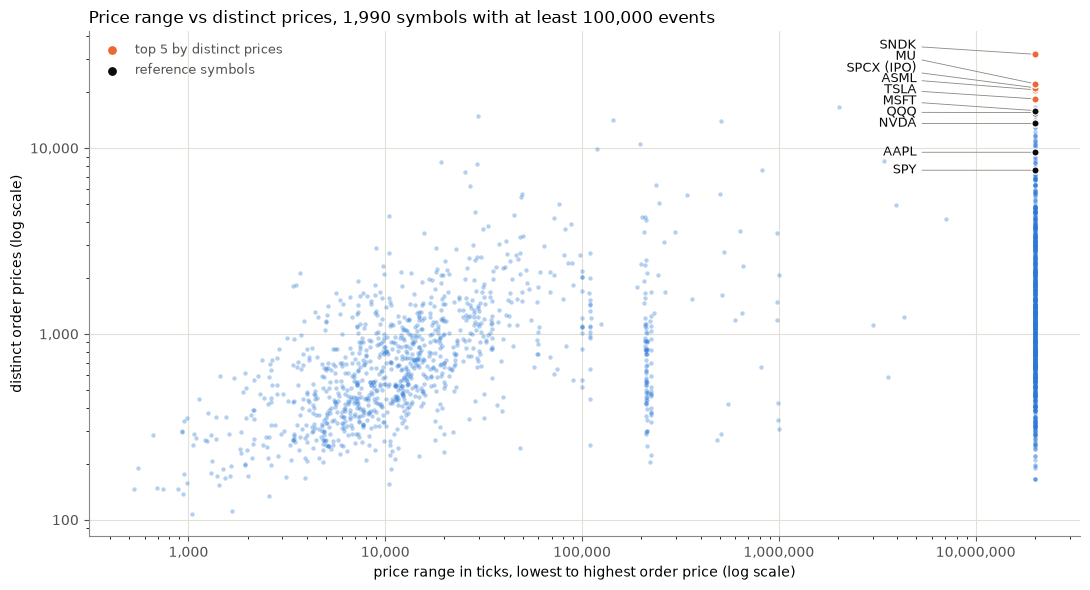

In [23]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(
    active_price_profile["range_ticks"], active_price_profile["distinct_prices"],
    s=10, color="#2a78d6", alpha=0.35, linewidths=0,
)

# Highlighted symbols: labels sit left of their points and are pushed apart vertically (in log10 units),
# since most of them share the same range on the right edge.
LABEL_GAP = 0.06
label_log_y = None
for row in pl.concat([most_distinct, references]).unique("symbol").sort("distinct_prices").iter_rows(named=True):
    is_outlier = row["symbol"] in most_distinct["symbol"]
    ax.scatter(
        row["range_ticks"], row["distinct_prices"], s=28, color="#eb6834" if is_outlier else "#0b0b0b",
        edgecolors="#fcfcfb", linewidths=1, zorder=3,
    )
    point_log_y = np.log10(row["distinct_prices"])
    label_log_y = point_log_y if label_log_y is None else max(point_log_y, label_log_y + LABEL_GAP)
    label = row["symbol"] + (" (IPO)" if row["ipo_flag"] == "Y" else "")
    ax.annotate(
        label, xy=(row["range_ticks"], row["distinct_prices"]), xytext=(row["range_ticks"] / 4, 10 ** label_log_y),
        ha="right", va="center", fontsize=9, color="#0b0b0b",
        arrowprops=dict(arrowstyle="-", color="#898781", linewidth=0.6, shrinkA=2, shrinkB=3),
    )
ax.scatter([], [], s=28, color="#eb6834", label=f"top {N_OUTLIERS} by distinct prices")
ax.scatter([], [], s=28, color="#0b0b0b", label="reference symbols")
ax.legend(frameon=False, fontsize=9, labelcolor="#52514e", loc="upper left")

ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:,.0f}"))
ax.set_xlabel("price range in ticks, lowest to highest order price (log scale)")
ax.set_ylabel("distinct order prices (log scale)")
ax.set_title(
    f"Price range vs distinct prices, {active_price_profile.height:,} symbols with at least {MIN_EVENTS:,} events",
    loc="left",
)
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#898781")
ax.tick_params(colors="#52514e")
fig.tight_layout()
plt.show()

### What the price profile shows

- **Stub quotes put orders at the edges of the price grid.** A stub quote is a placeholder order priced so far from
  the market that it will never trade, e.g. a bid at $0.0001 or an ask at $199,999. It keeps an order on each side of
  the book without any risk of a fill. Here there are about 17,000 of them, attributed (`F`) to a few dozen
  participants across over 4,000 symbols. About 15,000 are placed in one batch at 09:25, five minutes before the open,
  rest in the book through the whole session and are removed after 16:00. They are negligible as load (out of 817
  million orders), but they set the lowest and highest price of those symbols. They all use the same prices because
  those are the limits of the price grid: $0.0001 is the smallest price, and Nasdaq order entry accepts prices up to
  $199,999.99 ([OUCH 5.0 spec](https://nasdaqtrader.com/content/technicalsupport/specifications/TradingProducts/OUCH5.0.pdf)).
  Other participants use smaller caps of their own ($2,147.48, $999.99, ...): the smaller stripes in the scatter.
- **An array must cover the whole grid for 45% of the active symbols.** 898 of the 1,990 symbols have orders at both
  $0.0001 and $199,999 (first table): about 20 million ticks, of which they use 0.2% at most. An array indexed by price
  either covers that range or has to keep far-away orders outside its window. For these symbols the array is always
  sparse, so what tells the symbols apart is the number of distinct prices: the number of levels a tree has to hold.
- **Distinct prices separate the symbols.** The median active symbol uses about 850 different prices over the day,
  90% use fewer than 3,300. The widest books are high-priced stocks, where a small move in percent covers many ticks:
  SNDK (31,940 prices, ~$1,956), MU (22,174, ~$985), ASML (20,577, ~$1,863), TSLA (18,385, ~$400). SPCX is the day's
  IPO and is excluded from selection.
- **The narrowest active books are low-priced names without stub quotes.** The bottom five (four ETFs and one ADR,
  $2–$9 on average) use 108–146 prices over ranges of 885–2,580 ticks, 5–17% of their range. Each symbol has its own
  book, so for symbols like these a dense array of a few thousand slots fits well.
- **The popular names are not the typical case.** MSFT, QQQ, NVDA, AAPL and SPY use 7,600–15,900 prices, far above
  the median; they are busy, wide books. A typical-load candidate has to come from the middle of the cloud instead.

Still missing: where most orders actually land, i.e. the price range without the stub quotes.

In [24]:
LOWEST_PRICE_PX = 1  # $0.0001, the smallest price on the grid
STUB_CEILING_PX = 1_999_990_000  # $199,999, where the stub asks sit (order entry accepts up to $199,999.99)

# Symbols on the wall: orders at both edges of the grid, so their range is pinned at ~20M ticks.
wall_locates = active_price_profile.filter(
    (pl.col("min_px") <= LOWEST_PRICE_PX) & (pl.col("max_px") >= STUB_CEILING_PX)
)["locate"].to_list()

# Same profile, without the orders at the grid edges ($0.0001 and $199,999 and above).
price_profile_no_edges = (
    arrivals
    .join(active_price_profile.select("locate").lazy(), on="locate", how="semi")
    .filter(pl.col("price") > LOWEST_PRICE_PX, pl.col("price") < STUB_CEILING_PX)
    .group_by("locate")
    .agg(
        pl.len().alias("orders"),
        pl.col("price").min().alias("min_px"),
        pl.col("price").max().alias("max_px"),
        pl.col("price").approx_n_unique().alias("distinct_prices"),  # HyperLogLog estimate, ~1% error
    )
    .with_columns((tick_index(pl.col("max_px")) - tick_index(pl.col("min_px")) + 1).alias("range_ticks"))
    .with_columns(pl.col("locate").is_in(wall_locates).alias("was_on_wall"))
    .join(active_price_profile.select("locate", "symbol").lazy(), on="locate", how="left")
    .collect(engine="streaming")
)
print(
    f"{price_profile_no_edges.height:,} symbols, {len(wall_locates):,} of them were on the wall; "
    f"{active_price_profile['orders'].sum() - price_profile_no_edges['orders'].sum():,} grid-edge orders removed"
)

1,990 symbols, 898 of them were on the wall; 5,157 grid-edge orders removed


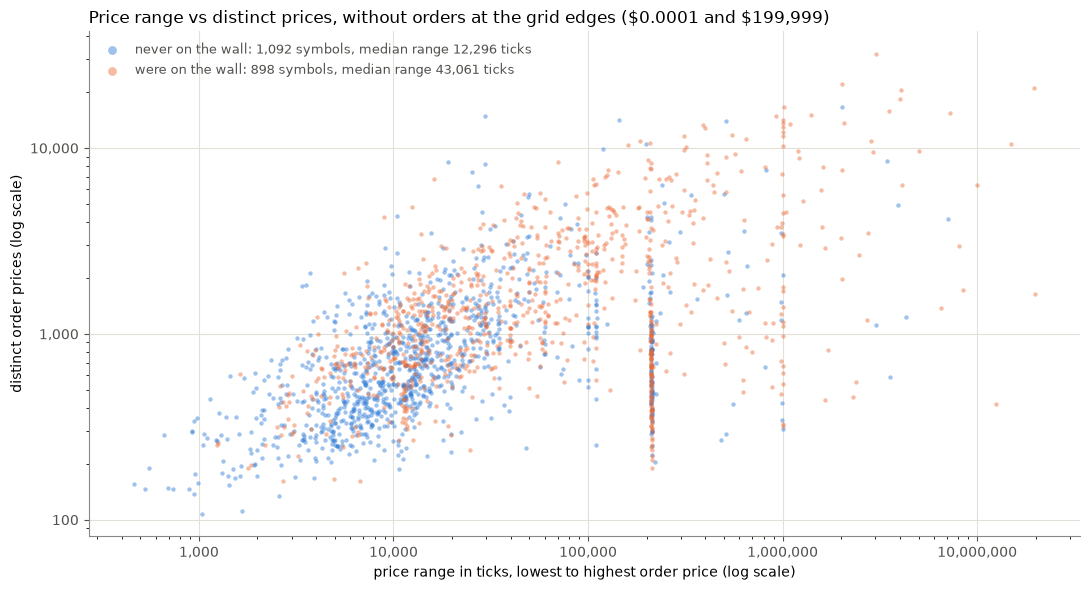

In [25]:
fig, ax = plt.subplots(figsize=(11, 6))
for was_on_wall, color, name in [(False, "#2a78d6", "never on the wall"), (True, "#eb6834", "were on the wall")]:
    group = price_profile_no_edges.filter(pl.col("was_on_wall") == was_on_wall)
    median_range = group["range_ticks"].median()
    ax.scatter(
        group["range_ticks"], group["distinct_prices"], s=10, color=color, alpha=0.45, linewidths=0,
        label=f"{name}: {group.height:,} symbols, median range {median_range:,.0f} ticks",
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:,.0f}"))
ax.set_xlabel("price range in ticks, lowest to highest order price (log scale)")
ax.set_ylabel("distinct order prices (log scale)")
ax.set_title("Price range vs distinct prices, without orders at the grid edges (\\$0.0001 and \\$199,999)", loc="left")
ax.legend(frameon=False, fontsize=9, labelcolor="#52514e", loc="upper left", markerscale=2)
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#898781")
ax.tick_params(colors="#52514e")
fig.tight_layout()
plt.show()

### Without the stub quotes

We removed the orders at the edges of the price grid ($0.0001, and $199,999 or above), i.e. the stub quotes, and
recomputed the profile. Symbols that were on the wall are shown in orange.

Without the stubs, many of them move into the main cloud next to the other symbols: 570 of the 898 now span less than
100,000 ticks. Their wide range came only from the stub quotes. As a group they stay somewhat wider than the others
(median range 43,061 vs 12,296 ticks).

## Choosing symbols by price pattern

The event mix does not separate load types, but the price profile does. Two numbers describe what a book structure
has to handle: the **range** of order prices (what an array indexed by price has to cover) and the number of
**distinct prices** (how many levels the book holds, e.g. the nodes of a tree). The selection uses the profile without
the stub quotes (plot above) and splits the symbols into five groups:

| Group | Range | Distinct prices | What it stresses |
|---|---|---|---|
| Wide and busy | high | high | many levels: tree depth, a wide array window |
| Wide and sparse | high | low | a few orders far from the rest: an array has to cover the gap or keep them outside its window |
| Narrow and dense | low | high share of the range | array best case: most slots in use |
| Narrow and small | low | low share of the range | a small book |
| Typical | middle | middle | realistic baseline |

Distinct prices can never exceed the range, so for narrow books their number alone is misleading: 300 prices is a lot
for a 400-tick range and little for a 30,000-tick one. For the narrow groups we therefore use the share of the range in
use, distinct prices / range in ticks. For wide books this share is close to zero for every symbol, since the range is
set by a few far-away orders, so there the absolute number of distinct prices is used.

Every candidate must also:
- have at least 100,000 events, so each workload has enough operations to measure;
- have no trading halt during the day;
- not be an IPO on this day (SPCX is excluded).

### Candidates

The next cell keeps the symbols that can serve as candidates:
- **at least 100,000 events** (`MIN_EVENTS`): `price_profile_no_edges` already holds only these;
- **not an IPO on this day**: the book of an IPO opens through an auction partway through the day (SPCX at 11:46),
  so its day is an outlier;
- **no halt during the day**, for simplicity: a halted, paused or quotation-only symbol would need special handling
  in the replay around those periods. Few symbols are affected on this day: 55 are halted, 28 paused by the Limit
  Up-Limit Down mechanism and 6 have a quotation-only period (counted over all symbols, before the event filter).

In [39]:
# Symbols with a halt, pause or quotation-only period during the day (any trading state other than "T").
halted_locates = halts.filter(pl.col("state") != "T").select("locate").unique().collect()["locate"].to_list()
ipo_locates = symbols.filter(pl.col("ipo_flag") == "Y").select("locate").collect()["locate"].to_list()

# Candidates: symbols with at least MIN_EVENTS events (price_profile_no_edges holds only those),
# without a halt and not an IPO, with the profile computed without the stub quotes.
candidates = (
    price_profile_no_edges
    .join(event_mix_per_symbol.select("locate", "events"), on="locate", how="left")
    .filter(~pl.col("locate").is_in(halted_locates), ~pl.col("locate").is_in(ipo_locates))
    .with_columns((pl.col("distinct_prices") / pl.col("range_ticks")).alias("density"))
    .select("symbol", "locate", "events", "orders", "min_px", "max_px", "range_ticks", "distinct_prices", "density")
    .sort("events", descending=True)
)

active = set(price_profile_no_edges["locate"])
print(f"{len(active):,} symbols with at least {MIN_EVENTS:,} events")
print(f"  - {len(active & set(halted_locates)):,} with a halt, pause or quotation-only period")
print(f"  - {len(active & set(ipo_locates) - set(halted_locates)):,} more that are an IPO")
print(f"{candidates.height:,} candidates left")

1,990 symbols with at least 100,000 events
  - 10 with a halt, pause or quotation-only period
  - 0 more that are an IPO
1,980 candidates left


### Narrow selection

In [40]:
NARROW_RANGE_TICKS = 3_000  # narrow books: at most ~$30 between the lowest and highest order price (from $1 up)

# Narrow candidates, sorted by the share of their range in use (distinct prices / range in ticks).
narrow = (
    candidates
    .filter(pl.col("range_ticks") <= NARROW_RANGE_TICKS)
    .join(price_profile.select("locate", "mean_price_usd"), on="locate", how="left")
    .select("symbol", "events", "mean_price_usd", "min_px", "max_px", "range_ticks", "distinct_prices", "density")
    .sort("density")
)
print(f"{narrow.height:,} candidates with a range of at most {NARROW_RANGE_TICKS:,} ticks")

display(Markdown("**Narrow and small: lowest share of the range in use**"))
display(narrow.head(10))
display(Markdown("**Narrow and dense: highest share of the range in use**"))
display(narrow.tail(10).sort("density", descending=True))

103 candidates with a range of at most 3,000 ticks


**Narrow and small: lowest share of the range in use**

symbol,events,mean_price_usd,min_px,max_px,range_ticks,distinct_prices,density
str,u32,f64,i64,i64,i64,u32,f64
"""MSC""",149396,2.531773,9320,199900,2580,135,0.052326
"""BITO""",156325,11.263288,10000,280000,2701,162,0.059978
"""DAMD""",149431,1.975219,9020,78000,1661,112,0.067429
"""DOG""",126465,22.259642,91600,355200,2637,196,0.074327
"""SCHH""",126454,24.152938,97400,382800,2855,219,0.076708
"""ETHT""",108263,8.63444,35100,290000,2550,216,0.084706
"""GSOL""",145885,5.059966,20300,220000,1998,173,0.086587
"""NVDQ""",692690,11.53449,47200,298000,2509,246,0.098047
"""GLL""",366360,24.782943,102100,395900,2939,291,0.099013


**Narrow and dense: highest share of the range in use**

symbol,events,mean_price_usd,min_px,max_px,range_ticks,distinct_prices,density
str,u32,f64,i64,i64,i64,u32,f64
"""IREZ""",559543,4.983001,23100,89300,663,285,0.429864
"""AAOG""",153225,10.250954,25000,168800,1439,596,0.414177
"""AMPU""",193022,8.502811,39200,152600,1135,445,0.39207
"""AS""",144311,37.542128,272000,434400,1625,606,0.372923
"""ONDU""",118893,7.226057,32800,127200,945,339,0.35873
"""COIA""",110087,8.103011,30900,129100,983,351,0.35707
"""CRCD""",239457,5.00975,19200,74500,554,190,0.34296
"""INFH""",135151,12.806165,55000,225600,1707,576,0.337434
"""VZLA""",108387,3.566419,13900,60000,462,155,0.335498


### Narrow groups: chosen symbols

Both symbols fit their group well and are busy enough to give a large workload:
- **Narrow and small: NVDQ.** About 10% of its range in use, with almost 700,000 events.
- **Narrow and dense: IREZ.** The highest share of its range in use, almost 43%, with almost 560,000 events.

**What these are.** Both are ETFs: funds whose shares trade on an exchange like a normal stock. Each of them tracks a
single company, in the opposite direction and doubled, and the target resets every day:
- **NVDQ** tracks NVIDIA: if NVIDIA's price goes up 1% in a day, NVDQ aims to go down 2%, and the other way round.
- **IREZ** does the same for IREN, a company that mines bitcoin and runs data centers.

People use such funds to bet against a stock for a short time or to protect against its fall.

### Wide and sparse selection

In [41]:
WIDE_RANGE_TICKS = 1_000_000  # wide books: at least ~$10,000 between the lowest and highest order price

# Wide candidates, fewest distinct prices first: a few orders spread over a very wide range.
wide = (
    candidates
    .filter(pl.col("range_ticks") >= WIDE_RANGE_TICKS)
    .join(price_profile.select("locate", "mean_price_usd"), on="locate", how="left")
    .select("symbol", "events", "mean_price_usd", "min_px", "max_px", "range_ticks", "distinct_prices", "density")
    .sort("distinct_prices")
)
print(f"{wide.height:,} candidates with a range of at least {WIDE_RANGE_TICKS:,} ticks")

display(Markdown("**Wide and sparse: fewest distinct prices**"))
display(wide.head(10))

61 candidates with a range of at least 1,000,000 ticks


**Wide and sparse: fewest distinct prices**

symbol,events,mean_price_usd,min_px,max_px,range_ticks,distinct_prices,density
str,u32,f64,i64,i64,i64,u32,f64
"""GME""",119539,42.185545,100,1249990000,12509701,418,0.000033
"""T""",235134,29.949734,2300,230000000,2307601,457,0.000198
"""BMNR""",757693,16.830052,1600,100000000,1008301,540,0.000536
"""VSME""",670348,2.814775,100,238000000,2389801,549,0.00023
"""ARKX""",178732,34.292499,143500,356700000,3565566,585,0.000164
"""BBAI""",118494,11.370001,100,100000000,1009801,617,0.000611
"""RZLV""",170667,5.407996,1000,100000000,1008901,672,0.000666
"""GMM""",221619,6.697423,100,170268500,1712486,817,0.000477
"""XYZ""",1132182,70.581762,6900,99990000,1002901,1100,0.001097


### Wide and sparse: chosen symbol

- **Wide and sparse: BMNR.** Only 540 distinct prices over a range of at least a million ticks, with about 757,000
  events.

**What it is.** BMNR is BitMine Immersion Technologies, a US company whose main asset is the cryptocurrency Ethereum:
it sells new shares and uses the money to buy Ethereum, so its share price mostly follows the price of Ethereum.

### Wide and busy selection

In [45]:
WIDE_BUSY_RANGE_TICKS = 5_000_000  # very wide books: at least ~$50,000 between the lowest and highest order price

# Very wide candidates, most distinct prices first: many levels spread over a very wide range.
wide_busy = (
    candidates
    .filter(pl.col("range_ticks") >= WIDE_BUSY_RANGE_TICKS)
    .join(price_profile.select("locate", "mean_price_usd"), on="locate", how="left")
    .select("symbol", "events", "mean_price_usd", "min_px", "max_px", "range_ticks", "distinct_prices", "density")
    .sort("distinct_prices", descending=True)
)
print(f"{wide_busy.height:,} candidates with a range of at least {WIDE_BUSY_RANGE_TICKS:,} ticks")

display(Markdown("**Wide and busy: most distinct prices**"))
display(wide_busy.head(10))

10 candidates with a range of at least 5,000,000 ticks


**Wide and busy: most distinct prices**

symbol,events,mean_price_usd,min_px,max_px,range_ticks,distinct_prices,density
str,u32,f64,i64,i64,i64,u32,f64
"""QQQ""",28415132,719.736422,100,721600000,7225801,15517,0.002147
"""AMZN""",7213094,237.772675,100,1500000000,15009801,10450,0.000696
"""PLTR""",3718183,129.786727,100,500000000,5009801,9637,0.001924
"""ASTS""",1272756,87.045278,10,1000000000,10009891,6315,0.000631
"""RKLX""",761150,55.060066,100,707520000,7085001,4166,0.000588
"""SQQQ""",5726058,40.703826,100,808021200,8090013,2981,0.000368
"""CRCL""",683408,80.69638,150000,850000000,8498501,1727,0.000203
"""MNTS""",152468,45.068547,1000,1980000000,19808901,1639,0.000083
"""QLD""",4732988,93.110388,330000,654878800,6545489,1379,0.000211


### Wide and busy: chosen symbol

- **Wide and busy: AMZN.** About 10,450 distinct prices over a range of about 15 million ticks (orders from $0.01 up
  to $150,000), with about 7.2 million events.

**What it is.** AMZN is Amazon, the online retailer and cloud computing company: one of the largest and most traded
US stocks, at around $238 a share on this day.

### Typical selection

The typical group should stand for an ordinary symbol, not an extreme one. Every candidate is ranked on both axes, by
range and by number of distinct prices. Its percentile is the share of candidates with a smaller value, so 0.5 is the
median. A symbol close to the 50th percentile on both axes sits in the middle of the cloud in the plot: neither
unusually wide nor narrow, with neither many nor few price levels. That is what we take as typical.

The band is ±5 percentiles (45th to 55th) on both axes. With ±1 percentile no symbol was left: few symbols are close
to the median on both axes at once.

In [49]:
TYPICAL_BAND = 0.05  # keep symbols within ±5 percentiles of the median on both axes

# Percentile rank of every candidate on both axes (0 = lowest, 1 = highest), then the symbols close to the median on both.
typical = (
    candidates
    .with_columns(
        (pl.col("range_ticks").rank() / pl.len()).alias("range_percentile"),
        (pl.col("distinct_prices").rank() / pl.len()).alias("distinct_percentile"),
    )
    .filter(
        (pl.col("range_percentile") - 0.5).abs() <= TYPICAL_BAND,
        (pl.col("distinct_percentile") - 0.5).abs() <= TYPICAL_BAND,
    )
    .join(price_profile.select("locate", "mean_price_usd"), on="locate", how="left")
    .select("symbol", "events", "mean_price_usd", "range_ticks", "distinct_prices", "range_percentile", "distinct_percentile")
    .sort("events", descending=True)
)
print(
    f"median range {candidates['range_ticks'].median():,.0f} ticks, "
    f"median distinct prices {candidates['distinct_prices'].median():,.0f}"
)
print(f"{typical.height:,} candidates within ±{TYPICAL_BAND:.0%} of the median on both axes")

display(Markdown("**Typical: closest to the median on both axes**"))
display(typical)

median range 18,070 ticks, median distinct prices 844
23 candidates within ±5% of the median on both axes


**Typical: closest to the median on both axes**

symbol,events,mean_price_usd,range_ticks,distinct_prices,range_percentile,distinct_percentile
str,u32,f64,i64,u32,f64,f64
"""VYM""",1147243,161.050746,18887,934,0.511111,0.548232
"""B""",1077287,39.835761,15101,821,0.456566,0.485859
"""FBL""",509332,21.584736,19061,842,0.516667,0.49899
"""CM""",348917,113.447301,17757,923,0.49596,0.541667
"""QQEW""",320058,153.28322,21976,852,0.54899,0.505303
…,…,…,…,…,…,…
"""SLF""",137426,76.594909,17842,786,0.496465,0.463636
"""QVOL""",124466,101.318815,16599,797,0.479798,0.472475
"""DWAS""",107014,118.414598,18691,923,0.509091,0.541667


There are 23 candidates in this band, more than we need. To choose among them, we raise the event limit to
500,000 and keep only the busier ones: the more events, the larger the workload the symbol gives.

In [50]:
TYPICAL_MIN_EVENTS = 500_000  # among the typical candidates, only the busier ones

typical_busy = typical.filter(pl.col("events") >= TYPICAL_MIN_EVENTS)
print(f"{typical_busy.height:,} of the {typical.height:,} typical candidates have at least {TYPICAL_MIN_EVENTS:,} events")
typical_busy

3 of the 23 typical candidates have at least 500,000 events


symbol,events,mean_price_usd,range_ticks,distinct_prices,range_percentile,distinct_percentile
str,u32,f64,i64,u32,f64,f64
"""VYM""",1147243,161.050746,18887,934,0.511111,0.548232
"""B""",1077287,39.835761,15101,821,0.456566,0.485859
"""FBL""",509332,21.584736,19061,842,0.516667,0.49899


### Typical: chosen symbol

- **Typical: B.** 821 distinct prices over a range of 15,101 ticks (medians of all candidates: 844 and 18,070), with
  about 1.1 million events.

**What it is.** B is Barrick Mining, one of the world's largest gold and copper miners, based in Canada. Its share
price moves largely with the prices of gold and copper.

### Selected symbols

| Group | Range | Distinct prices | What it stresses | Selected symbol |
|---|---|---|---|---|
| Wide and busy | high | high | many levels: tree depth, a wide array window | AMZN |
| Wide and sparse | high | low | a few orders far from the rest: an array has to cover the gap or keep them outside its window | BMNR |
| Narrow and dense | low | high share of the range | array best case: most slots in use | IREZ |
| Narrow and small | low | low share of the range | a small book | NVDQ |
| Typical | middle | middle | realistic baseline | B |